CSET485 Assignment 1: German Credit, roll suffix 044
This is an explanatory analysis, not a lending deployment model.
Source: https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
UCI's good/bad risk labels are proxies for the assignment's approve/reject,
not observed historical approval decisions. Positive always means approve.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, urllib.request, warnings
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import statsmodels.api as sm
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, brier_score_loss
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED = 44
ROOT = Path.cwd()
if (ROOT / 'outputs' / 'data' / 'german.data').exists():
    ROOT = ROOT / 'outputs'
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
if not (DATA / 'german.data').exists():
    urllib.request.urlretrieve(URL, DATA / 'german.data')
data_hash = hashlib.sha256((DATA / 'german.data').read_bytes()).hexdigest()
print('Seed:', SEED, '| SHA256:', data_hash)



Seed: 44 | SHA256: b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871


Preprocessing: validate all 1,000 rows; retain all valid outliers; no imputation
is needed for this file. 'Unknown/no savings' is a documented category, not NaN.
Fit numeric scaling and categorical vocabulary on training rows only. Drop one
reference level per categorical variable; retain the same scales/references
when dropping a confounder. No target, row ID, or derived sex is added to X.
The derived sex group is only used for auditing (the original combined
personal-status/sex feature remains in the required full model).


In [2]:
columns = ['checking', 'duration', 'history', 'purpose', 'amount', 'savings',
           'employment', 'installment', 'personal_status', 'guarantor',
           'residence', 'property', 'age', 'other_plans', 'housing',
           'existing_credits', 'job', 'dependents', 'telephone', 'foreign_worker', 'label']
numeric = ['duration', 'amount', 'installment', 'residence', 'age', 'existing_credits', 'dependents']
categorical = [c for c in columns[:-1] if c not in numeric]
df = pd.read_csv(DATA / 'german.data', sep=r'\s+', names=columns)
df.index.name = 'source_row_zero_based'
assert df.shape == (1000, 21) and not df.isna().any().any()
assert set(df.label) == {1, 2}
df['approve'] = (df.label == 1).astype(int)
sex_map = {'A91': 'Male', 'A92': 'Female', 'A93': 'Male', 'A94': 'Male', 'A95': 'Female'}
df['sex'] = df.personal_status.map(sex_map)
assert df.sex.notna().all()
train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=df.approve)
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()
mean, scale = train[numeric].mean(), train[numeric].std(ddof=0)
levels = {c: sorted(train[c].unique()) for c in categorical}
def design(frame):
    z = (frame[numeric] - mean) / scale
    for c in categorical:
        unknown = set(frame[c]) - set(levels[c])
        if unknown:
            raise ValueError(f'Unseen category in {c}: {unknown}')
        for level in levels[c][1:]:
            z[f'{c}_{level}'] = (frame[c] == level).astype(float)
    return sm.add_constant(z.astype(float), has_constant='add')
Xtr, Xte = design(train), design(test)
ytr, yte = train.approve, test.approve
assert np.linalg.matrix_rank(Xtr.to_numpy()) == Xtr.shape[1]
outliers = []
for c in numeric:
    q1, q3 = train[c].quantile([.25, .75]); iqr = q3-q1
    outliers.append({'feature': c, 'train_min': train[c].min(), 'train_max': train[c].max(),
                     'train_1.5IQR_count': int(((train[c] < q1-1.5*iqr)|(train[c] > q3+1.5*iqr)).sum())})
pd.DataFrame(outliers).to_csv(RESULTS / 'outlier_audit.csv', index=False)
print('Train/test:', len(train), len(test), '| approvals:', ytr.sum(), yte.sum())
print('Design columns including intercept:', Xtr.shape[1])
print('References:', {c: levels[c][0] for c in categorical})



Train/test: 700 300 | approvals: 490 210
Design columns including intercept: 49
References: {'checking': 'A11', 'history': 'A30', 'purpose': 'A40', 'savings': 'A61', 'employment': 'A71', 'personal_status': 'A91', 'guarantor': 'A101', 'property': 'A121', 'other_plans': 'A141', 'housing': 'A151', 'job': 'A171', 'telephone': 'A191', 'foreign_worker': 'A201'}


Part 1: OLS is a linear probability model; predictions may fall outside [0,1].
Do not clip before the required median split. The assignment's comparison
matrix compares model labels to each other, not either model to ground truth.
We also report separate ground-truth confusion matrices to avoid confusion.


In [3]:
ols = sm.OLS(ytr, Xtr).fit()
# L2 regularization avoids quasi/perfect separation in rare purpose categories.
# C=1 is fixed in advance of evaluating this final model; no test-set tuning.
# The intercept is not penalized. The same C, rows and scaling are used in 2.2.
def fit_prediction_model(x,y):
    fitted = LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, tol=1e-9).fit(x.drop(columns='const'),y)
    assert fitted.n_iter_[0] < 2000
    fitted.params = pd.Series(np.r_[fitted.intercept_[0],fitted.coef_[0]],index=x.columns)
    return fitted
logit = fit_prediction_model(Xtr,ytr)
linear_predictions = ols.predict(Xte)
prob = pd.Series(logit.predict_proba(Xte.drop(columns='const'))[:,1],index=test.index)
median = float(linear_predictions.median())
pred_a = (linear_predictions >= median).astype(int)
pred_b = (prob >= .5).astype(int)
agreement = pd.DataFrame(confusion_matrix(pred_a, pred_b, labels=[0,1]),
                         index=['OLS reject', 'OLS approve'], columns=['Logit reject', 'Logit approve'])
mismatch_n = int((pred_a != pred_b).sum())
comparison = test.copy()
comparison['ols_score'] = linear_predictions
comparison['logit_probability'] = prob
comparison['ols_decision'] = pred_a
comparison['logit_decision_0.5'] = pred_b
comparison.to_csv(RESULTS / 'test_predictions.csv')
agreement.to_csv(RESULTS / 'model_agreement.csv')
coef = pd.DataFrame({'coefficient_L2_C1': logit.params})
coef.to_csv(RESULTS / 'full_model_coefficients.csv')
summary = {'seed': SEED, 'sha256': data_hash, 'train_n': len(train), 'test_n': len(test),
           'median_ols': median, 'mismatch_n': mismatch_n, 'mismatch_pct': 100*mismatch_n/len(test),
           'ols_approved': int(pred_a.sum()), 'logit_approved': int(pred_b.sum()),
           'ols_accuracy': accuracy_score(yte,pred_a), 'logit_accuracy': accuracy_score(yte,pred_b),
           'logit_auc': roc_auc_score(yte,prob), 'logit_brier': brier_score_loss(yte,prob),
           'ols_outside_01': int(((linear_predictions<0)|(linear_predictions>1)).sum())}
print(agreement.to_string())
print(json.dumps(summary, indent=2))
print('Logit versus truth (rows actual 0,1; columns predicted 0,1):\n', confusion_matrix(yte,pred_b))



             Logit reject  Logit approve
OLS reject             67             83
OLS approve             0            150
{
  "seed": 44,
  "sha256": "b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871",
  "train_n": 700,
  "test_n": 300,
  "median_ols": 0.6927325910393574,
  "mismatch_n": 83,
  "mismatch_pct": 27.666666666666668,
  "ols_approved": 150,
  "logit_approved": 233,
  "ols_accuracy": 0.68,
  "logit_accuracy": 0.7433333333333333,
  "logit_auc": 0.787883597883598,
  "logit_brier": 0.16637606604112828,
  "ols_outside_01": 49
}
Logit versus truth (rows actual 0,1; columns predicted 0,1):
 [[ 40  50]
 [ 27 183]]


Part 2.1: exploratory subgroup hunt on all 1,000 rows, as requested, separately
from held-out prediction evaluation. Use a stable, interpretable numeric-only
model with all seven numeric predictors, globally standardized, in every fit.
This is deliberately a different explanatory specification from the full
prediction model. Search two declared partitions (sex; age <35 versus >=35)
and seven numeric predictors. Export every result; use Bonferroni over all
14 between-group comparisons, rather than choosing an unadjusted p-value.
Since the groups are disjoint, SE(beta_A-beta_B)=sqrt(SE_A^2+SE_B^2).
These are conditional associations, not causal effects. A sign change alone
with wide intervals is not established Simpson's paradox.


In [4]:
all_z = sm.add_constant(((df[numeric]-mean)/scale).astype(float), has_constant='add')
pooled = sm.GLM(df.approve, all_z, family=sm.families.Binomial()).fit(cov_type='HC0')
partitions = {'sex': df.sex == 'Female', 'age35': df.age < 35}
subgroup_fits, hunt_rows = {}, []
for partition, mask in partitions.items():
    fits = []
    for keep in [mask, ~mask]:
        fit = sm.GLM(df.loc[keep,'approve'], all_z.loc[keep], family=sm.families.Binomial()).fit(cov_type='HC0')
        assert fit.converged
        fits.append(fit)
    subgroup_fits[partition] = fits
    for feature in numeric:
        a,b = fits
        delta = a.params[feature]-b.params[feature]
        delta_se = np.sqrt(a.bse[feature]**2+b.bse[feature]**2)
        p = 2*norm.sf(abs(delta/delta_se))
        hunt_rows.append({'partition': partition, 'feature': feature,
                         'pooled_beta': pooled.params[feature],
                         'pooled_low': pooled.conf_int().loc[feature,0], 'pooled_high': pooled.conf_int().loc[feature,1],
                         'A_n': int(mask.sum()), 'B_n': int((~mask).sum()),
                         'A_beta': a.params[feature], 'A_low': a.conf_int().loc[feature,0], 'A_high': a.conf_int().loc[feature,1],
                         'B_beta': b.params[feature], 'B_low': b.conf_int().loc[feature,0], 'B_high': b.conf_int().loc[feature,1],
                         'difference': delta, 'difference_SE': delta_se, 'p':p})
hunt = pd.DataFrame(hunt_rows)
hunt['p_bonferroni'] = np.minimum(1, len(hunt)*hunt.p)
hunt = hunt.sort_values('p')
hunt.to_csv(RESULTS / 'subgroup_hunt_all_comparisons.csv', index=False)
selected = hunt.iloc[0].to_dict()
print(hunt.to_string(index=False, float_format=lambda x:f'{x:.5f}'))
print('Selected strongest evidence (exploratory):', json.dumps(selected, indent=2))



partition          feature  pooled_beta  pooled_low  pooled_high  A_n  B_n   A_beta    A_low   A_high   B_beta    B_low   B_high  difference  difference_SE       p  p_bonferroni
      sex              age      0.24388     0.07912      0.40865  310  690  0.51246  0.23923  0.78569  0.04355 -0.16251  0.24961     0.46890        0.17461 0.00724       0.10139
    age35              age      0.24388     0.07912      0.40865  548  452  0.50236 -0.09378  1.09849 -0.23900 -0.51481  0.03680     0.74136        0.33513 0.02696       0.37739
    age35       dependents     -0.04516    -0.18729      0.09696  548  452  0.02464 -0.21086  0.26015 -0.21590 -0.41708 -0.01473     0.24055        0.15803 0.12796       1.00000
      sex        residence     -0.04484    -0.18993      0.10026  310  690 -0.14234 -0.38244  0.09776  0.06629 -0.12353  0.25611    -0.20863        0.15616 0.18155       1.00000
    age35 existing_credits      0.08985    -0.06054      0.24025  548  452 -0.01929 -0.23443  0.19585  0.18822

Part 2.2: omit duration, a plausible shared driver of credit amount and risk.
The same training rows and original coding/scales are retained. Full means
all 20 usable predictors, not the outcome/derived fields. Changes in logistic
coefficients can also reflect non-collapsibility; they do not prove causal
confounding. Percentage change uses 100*(reduced-full)/abs(full), with the
denominator stated explicitly; near-zero coefficients make percentages unstable.


In [5]:
reduced = fit_prediction_model(Xtr.drop(columns='duration'),ytr)
ovb = pd.DataFrame({'full': logit.params, 'without_duration': reduced.params}).drop(index=['const','duration'])
ovb['change'] = ovb.without_duration-ovb.full
ovb['percent_change_abs_denominator'] = 100*ovb.change/ovb.full.abs().replace(0,np.nan)
ovb['absolute_percent_change'] = ovb.percent_change_abs_denominator.abs()
ovb.to_csv(RESULTS / 'omitted_variable_all_coefficients.csv')
ovb_four = ovb.loc[['amount','installment','age','existing_credits']]
print('Correlation of duration with amount (training):', train.duration.corr(train.amount))
print(ovb_four.to_string())
print('Largest relative shift among four:', ovb_four.absolute_percent_change.idxmax())
print('Largest relative shift among all retained predictors:', ovb.absolute_percent_change.idxmax())
print('Largest absolute coefficient shift among all:', ovb.change.abs().idxmax())



Correlation of duration with amount (training): 0.6174141868906872
                      full  without_duration    change  percent_change_abs_denominator  absolute_percent_change
amount           -0.345292         -0.489536 -0.144244                      -41.774669                41.774669
installment      -0.397775         -0.449130 -0.051355                      -12.910534                12.910534
age               0.184227          0.197158  0.012931                        7.018901                 7.018901
existing_credits -0.151467         -0.142686  0.008782                        5.797808                 5.797808
Largest relative shift among four: amount
Largest relative shift among all retained predictors: purpose_A46
Largest absolute coefficient shift among all: amount


Part 2.3: identify confident mistakes using held-out outcomes only, then sample
with seed 44 if more than 50 exist. This is a retrospective error audit, not a
representative evaluation subset and not a new training set. Describing an
enriched trait is evidence of a failure pattern, not proof of its mechanism.


In [6]:
wrong_mask = ((prob>=.75)&(yte==0)) | ((prob<=.25)&(yte==1))
wrong = comparison.loc[wrong_mask].copy()
adversarial = wrong.sample(n=min(50,len(wrong)), random_state=SEED)
adversarial.to_csv(RESULTS / 'adversarial_subset.csv')
wrong.to_csv(RESULTS / 'all_confident_errors.csv')
summary.update({'confident_wrong_n': len(wrong), 'confident_wrong_pct': 100*len(wrong)/len(test),
                'adversarial_n': len(adversarial),
                'confident_false_approvals': int(((prob>=.75)&(yte==0)).sum()),
                'confident_false_rejections': int(((prob<=.25)&(yte==1)).sum())})
demographics = []
for name,frame in [('Test set',test),('All confident errors',wrong),('Sampled subset',adversarial)]:
    demographics.append({'population':name, 'n':len(frame), 'mean_age':frame.age.mean(),
                         'median_age':frame.age.median(), 'age_min':frame.age.min(), 'age_max':frame.age.max(),
                         'female_pct':100*(frame.sex=='Female').mean(), 'male_pct':100*(frame.sex=='Male').mean(),
                         'actual_approve_pct':100*frame.approve.mean()})
demographics = pd.DataFrame(demographics)
demographics.to_csv(RESULTS / 'adversarial_demographics.csv',index=False)
traits = {'checking A14 (no checking account)':lambda f:f.checking=='A14',
          'checking A11/A12 (balance below 200 DM)':lambda f:f.checking.isin(['A11','A12']),
          'duration <= 24 months':lambda f:f.duration<=24,
          'age <35':lambda f:f.age<35,
          'savings A61 (below 100 DM)':lambda f:f.savings=='A61',
          'existing credits paid duly A32':lambda f:f.history=='A32'}
trait_rows = []
for name,fn in traits.items():
    trait_rows.append({'trait':name, 'subset_pct':100*fn(adversarial).mean(),
                       'test_pct':100*fn(test).mean(), 'subset_count':int(fn(adversarial).sum())})
trait_table = pd.DataFrame(trait_rows)
trait_table['enrichment_percentage_points'] = trait_table.subset_pct-trait_table.test_pct
trait_table.to_csv(RESULTS / 'adversarial_traits.csv', index=False)
print(json.dumps({k:v for k,v in summary.items() if 'confident' in k or 'adversarial' in k},indent=2))
print(demographics.to_string(index=False)); print(trait_table.to_string(index=False))
# Local explanation: actual contribution to one confidently incorrect approval.
example = wrong.loc[wrong.approve==0].sort_values('logit_probability', ascending=False).iloc[0]
contributions = (Xte.loc[example.name] * logit.params).sort_values()
contributions.to_csv(RESULTS / 'confident_error_logit_contributions.csv', header=['log_odds_contribution'])
print('Example source row:', example.name, '| p:',example.logit_probability,'| actual:', example.approve)
print('Largest positive contributions:',contributions.tail(6).to_string())



{
  "confident_wrong_n": 19,
  "confident_wrong_pct": 6.333333333333333,
  "adversarial_n": 19,
  "confident_false_approvals": 15,
  "confident_false_rejections": 4
}
          population   n  mean_age  median_age  age_min  age_max  female_pct  male_pct  actual_approve_pct
            Test set 300 35.823333        34.0       20       75   29.333333 70.666667           70.000000
All confident errors  19 36.684211        34.0       21       66   10.526316 89.473684           21.052632
      Sampled subset  19 36.684211        34.0       21       66   10.526316 89.473684           21.052632
                                  trait  subset_pct  test_pct  subset_count  enrichment_percentage_points
     checking A14 (no checking account)   15.789474 34.333333             3                    -18.543860
checking A11/A12 (balance below 200 DM)   68.421053 58.333333            13                     10.087719
                  duration <= 24 months   73.684211 75.333333            14            

Part 2.4: Group A=Female, Group B=Male from the documented combined sex/status
field. It is a limited historical binary coding, not a complete gender measure.
Compute the assignment's exact directional ratios; do not silently symmetrize.
EO=min(TPR_A/TPR_B,FPR_A/FPR_B) is an assignment-specific summary and EO=1 alone
does NOT establish equalized odds. Export both component ratios and raw rates.
Undefined denominators yield NaN (NA in CSV); never replace 0/0 with 0 or 1.


 threshold     DP     EO     PP  TPR_ratio  FPR_ratio  accuracy  Female_selection  Male_selection  Female_TPR  Male_TPR  Female_FPR  Male_FPR
    0.0500 1.0000 1.0000 0.9636     1.0000     1.0000    0.7000            1.0000          1.0000      1.0000    1.0000      1.0000    1.0000
    0.1500 0.9845 0.9226 0.9921     1.0135     0.9226    0.7100            0.9659          0.9811      1.0000    0.9867      0.8929    0.9677
    0.2500 0.9828 0.9431 0.9838     1.0034     0.9431    0.7300            0.9318          0.9481      0.9833    0.9800      0.8214    0.8710
    0.3500 0.9714 0.9615 0.9538     0.9615     1.0299    0.7500            0.8523          0.8774      0.9167    0.9533      0.7143    0.6935
    0.4500 0.8748 0.8101 0.9978     0.9058     0.8101    0.7400            0.7386          0.8443      0.8333    0.9200      0.5357    0.6613
    0.5500 0.8379 0.6039 1.0557     0.9180     0.6039    0.7433            0.6364          0.7594      0.7833    0.8533      0.3214    0.5323
    0.

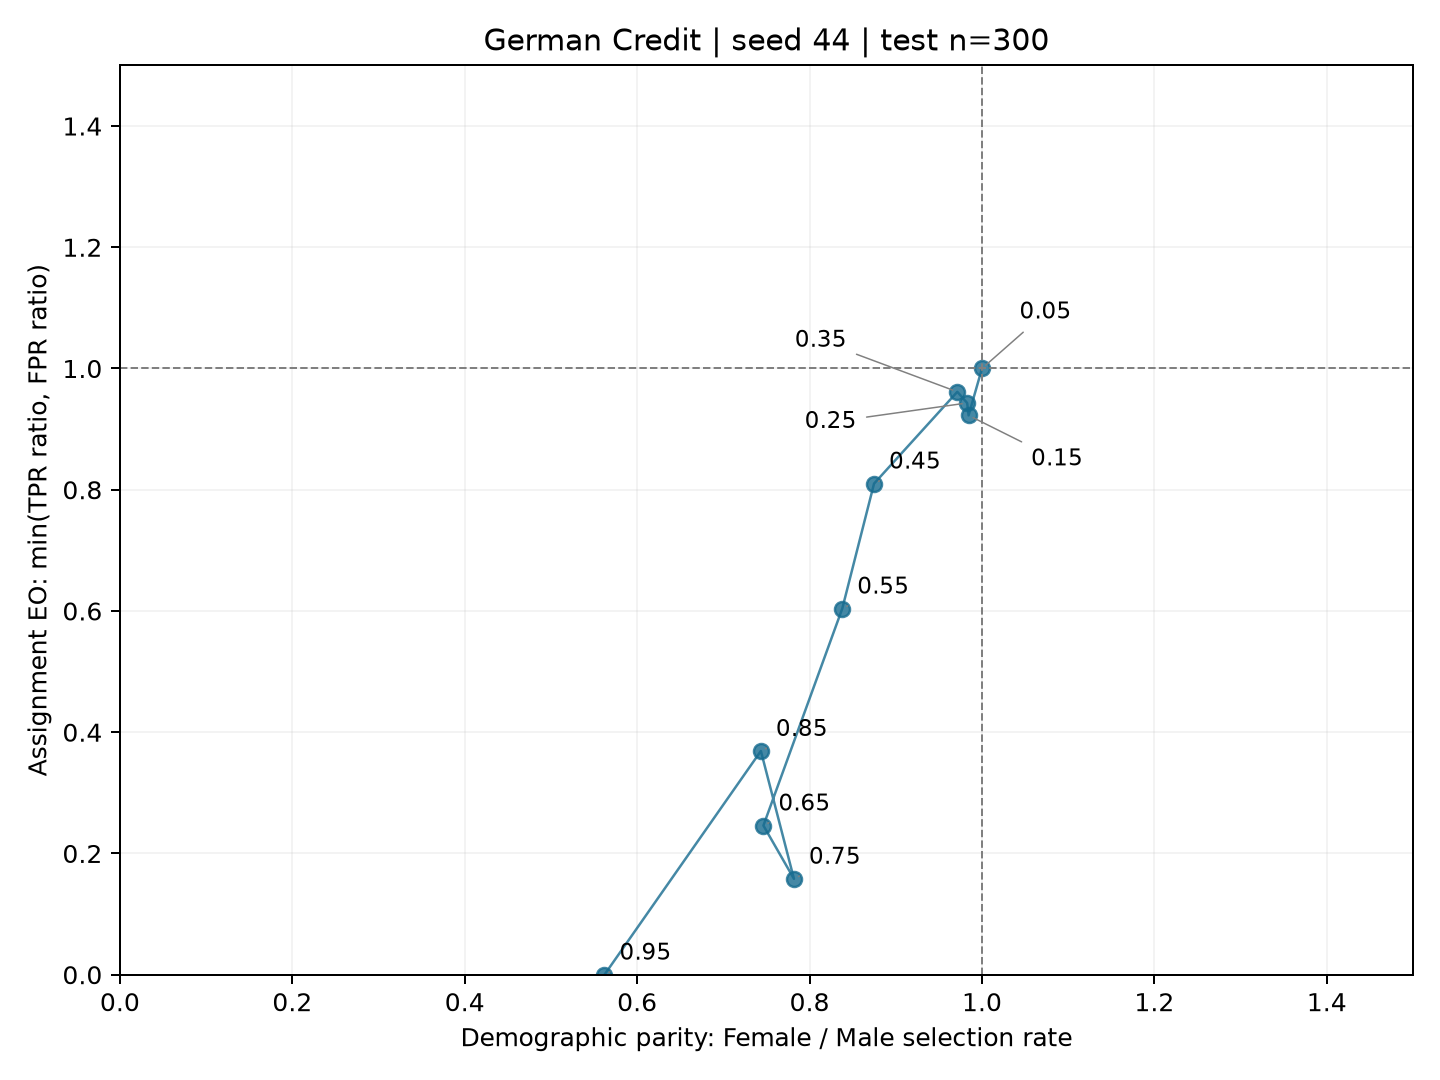

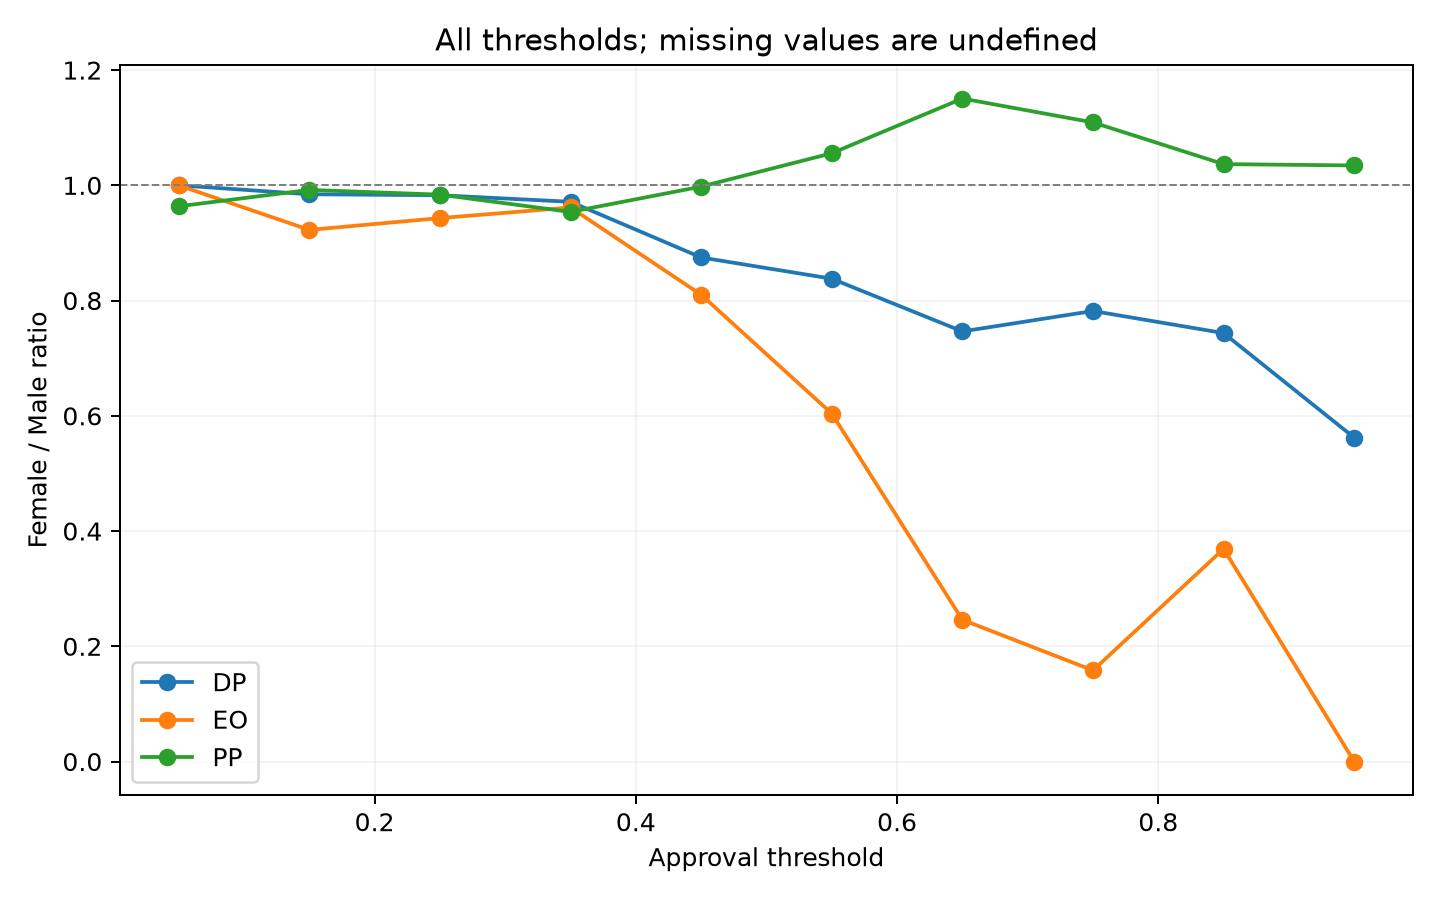

In [7]:
def divide(a,b):
    return float(a/b) if np.isfinite(a) and np.isfinite(b) and b!=0 else np.nan
def group_rates(actual, decision):
    tn,fp,fn,tp = confusion_matrix(actual,decision,labels=[0,1]).ravel()
    return {'n':len(actual),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'selection':float(np.mean(decision)), 'TPR':divide(tp,tp+fn),
            'FPR':divide(fp,fp+tn), 'PPV':divide(tp,tp+fp), 'accuracy':float(np.mean(actual==decision))}
fair_rows, raw_rates = [], []
for t in np.round(np.arange(.05,.951,.1),2):
    decision = (prob>=t).astype(int)
    groups={}
    for g in ['Female','Male']:
        mask = test.sex==g
        groups[g]=group_rates(yte[mask],decision[mask])
        raw_rates.append({'threshold':t,'group':g,**groups[g]})
    a,b=groups['Female'],groups['Male']
    tr,fr=divide(a['TPR'],b['TPR']),divide(a['FPR'],b['FPR'])
    eo=min(tr,fr) if np.isfinite(tr) and np.isfinite(fr) else np.nan
    fair_rows.append({'threshold':t,'DP':divide(a['selection'],b['selection']),
                      'EO':eo,'PP':divide(a['PPV'],b['PPV']), 'TPR_ratio':tr,'FPR_ratio':fr,
                      'accuracy':accuracy_score(yte,decision),
                      'Female_selection':a['selection'],'Male_selection':b['selection'],
                      'Female_TPR':a['TPR'],'Male_TPR':b['TPR'],
                      'Female_FPR':a['FPR'],'Male_FPR':b['FPR']})
fairness=pd.DataFrame(fair_rows)
rates=pd.DataFrame(raw_rates)
fairness.to_csv(RESULTS/'fairness_thresholds.csv',index=False,na_rep='NA')
rates.to_csv(RESULTS/'fairness_group_counts_rates.csv',index=False,na_rep='NA')
print(fairness.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
fig,ax=plt.subplots(figsize=(8,6))
valid=fairness.dropna(subset=['DP','EO'])
ax.plot(valid.DP,valid.EO,'o-',color='#166b8f',linewidth=1,alpha=.8)
offsets = {.05:(15,20), .15:(25,-20), .25:(-65,-10), .35:(-65,18)}
for _,r in valid.iterrows():
    ax.annotate(f"{r.threshold:.2f}",(r.DP,r.EO),xytext=offsets.get(r.threshold,(6,6)),
                textcoords='offset points',fontsize=9,
                arrowprops={'arrowstyle':'-','color':'gray','linewidth':.6})
ax.axvline(1,color='gray',linestyle='--',linewidth=.8); ax.axhline(1,color='gray',linestyle='--',linewidth=.8)
ax.set(xlabel='Demographic parity: Female / Male selection rate',
       ylabel='Assignment EO: min(TPR ratio, FPR ratio)',xlim=(0,1.5),ylim=(0,1.5),
       title='German Credit | seed 44 | test n=300')
ax.grid(alpha=.15); fig.tight_layout(); fig.savefig(RESULTS/'fairness_tradeoff.png',dpi=180); plt.close(fig)
# Also preserve unbounded values in a separate view to disclose clipping.
fig,ax=plt.subplots(figsize=(8,5))
for metric in ['DP','EO','PP']:
    ax.plot(fairness.threshold,fairness[metric],marker='o',label=metric)
ax.axhline(1,color='gray',linestyle='--',linewidth=.8)
ax.set(xlabel='Approval threshold',ylabel='Female / Male ratio',title='All thresholds; missing values are undefined')
ax.legend(); ax.grid(alpha=.15); fig.tight_layout(); fig.savefig(RESULTS/'fairness_by_threshold.png',dpi=180); plt.close(fig)



Quantify an observed trade-off without assuming that a larger ratio is always
fairer: define parity proximity = min(r,1/r) for r>0 (1=parity). Find all pairs
where DP proximity improves and EO proximity worsens; export them all. Also
print the raw-ratio changes for a pair entirely below 1, if one exists, which
matches the assignment's percentage-gain wording directly.
Threshold selection on this test set is exploratory, not an unbiased estimate
of a tuned policy. A future deployment needs separate validation and testing.


In [8]:
def proximity(r):
    return min(r,1/r) if np.isfinite(r) and r>0 else np.nan
tradeoffs=[]
for _,a in fairness.iterrows():
    for _,b in fairness.iterrows():
        da,db,ea,eb=map(proximity,[a.DP,b.DP,a.EO,b.EO])
        if np.isfinite([da,db,ea,eb]).all() and db>da+1e-8 and eb<ea-1e-8:
            gain=100*(db-da)/da; loss=100*(ea-eb)/ea
            tradeoffs.append({'from_threshold':a.threshold,'to_threshold':b.threshold,
                             'DP_from':a.DP,'DP_to':b.DP,'EO_from':a.EO,'EO_to':b.EO,
                             'DP_proximity_gain_pct':gain,'EO_proximity_loss_pct':loss,'cost':loss/gain})
trades=pd.DataFrame(tradeoffs)
trades.to_csv(RESULTS/'tradeoff_pairs.csv',index=False)
print('Trade-off pairs:\n',trades.to_string(index=False))
# Two real, anonymous records whose approvals change from t=.65 to t=.75.
scenario = comparison[(prob>=.65)&(prob<.75)].groupby('sex',sort=True).head(1).copy()
scenario['decision_at_0.65'] = (scenario.logit_probability>=.65).astype(int)
scenario['decision_at_0.75'] = (scenario.logit_probability>=.75).astype(int)
scenario.to_csv(RESULTS/'two_person_scenario.csv')
print('Two-person scenario:\n',scenario[['sex','age','approve','logit_probability','decision_at_0.65','decision_at_0.75']].to_string())
summary['subgroup_selected']=selected
summary['example_wrong_row']=int(example.name)
summary['example_wrong_probability']=float(example.logit_probability)
summary['duration_amount_correlation']=float(train.duration.corr(train.amount))
summary['versions']={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                     'scipy':scipy.__version__,'statsmodels':sm.__version__,'sklearn':sklearn.__version__,
                     'matplotlib':matplotlib.__version__}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
pd.DataFrame({'train_index':pd.Series(train_idx),'test_index':pd.Series(test_idx)}).to_csv(RESULTS/'split_indices.csv',index=False)
print('Saved all results to:',RESULTS)
print('Versions:',summary['versions'])



Trade-off pairs:
  from_threshold  to_threshold  DP_from    DP_to  EO_from    EO_to  DP_proximity_gain_pct  EO_proximity_loss_pct      cost
           0.25          0.15 0.982813 0.984484 0.943122 0.922619               0.170028               2.173913 12.785607
           0.35          0.15 0.971408 0.984484 0.961538 0.922619               1.346154               4.047619  3.006803
           0.35          0.25 0.971408 0.982813 0.961538 0.943122               1.174129               1.915344  1.631289
           0.65          0.75 0.746479 0.781898 0.246032 0.158163               4.744817              35.714286  7.527011
           0.85          0.65 0.743547 0.746479 0.369048 0.246032               0.394366              33.333333 84.523810
           0.85          0.75 0.743547 0.781898 0.369048 0.158163               5.157895              57.142857 11.078717
Two-person scenario:
                           sex  age  approve  logit_probability  decision_at_0.65  decision_at_0.75
source_

Interpretation checklist for the written responses:
1. Distinguish model agreement from ground-truth accuracy.
2. Quote subgroup coefficients, intervals, adjusted p-value, and model scope.
3. Quote four before/after coefficients; do not infer causality from shifts.
4. Propose a prospective audit including applicants the bank previously rejected.
5. Separate observed error patterns from untested explanations of their cause.
6. Use actual test rows when giving the two-person threshold scenario.
7. Name a defensible threshold with at least three metrics and a counterargument.
8. State whose harms matter when favoring one fairness criterion.
Reflection: use the evidence to justify a deployment decision and its limits.
Do not claim that every dataset must show a paradox or a fairness conflict.

# Working through CSET485 Assignment 1 — roll suffix 044

Your assigned dataset is **German Credit**, and your required split seed is **44**.
Start with this guide, then follow the matching notebook cells. The notebook has
already been executed; its saved outputs show the computed results. A full review draft is now available as `CSET485_044_Assignment_Report_Draft.pdf`,
with editable text in `CSET485_044_Report_Editable.md`. This walkthrough remains
a guide to understanding the analysis.

## What you are trying to demonstrate

A predictive model can look useful overall while its decisions depend on the
threshold, subgroup, omitted features, and definition of fairness. Your job is
to demonstrate those effects with measured results, then explain what they mean
for people. Do the analysis before writing the eight answers and reflection.

The assignment source is the PDF supplied in the chat. It requires a preprocessing
section, both prediction models, four stress tests, eight answers of about
250–300 words each, a reflection of about 500 words, one PDF report, and a GitHub
link to the reproducible notebook. Its deadline is **19 October 2026, 23:59 IST**.

## First understand the outcome

UCI calls label 1 **good credit risk** and label 2 **bad credit risk**. Following
the assignment, the notebook maps good risk to approve=1 and bad risk to reject=0.
These are risk labels used as approval proxies, not records of actual approval
decisions. Use “predicted approval” rather than “high risk” in your explanations:
a positive prediction has the opposite meaning from the COMPAS assignment route.

Dataset and original coding: [UCI German Credit](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data).
Citation: Hofmann, H. (1994), Statlog (German Credit Data), DOI 10.24432/C5NC77,
CC BY 4.0. The local data and codebook are in `data/`.

## Preprocessing: explain these decisions in your report

There are 1,000 rows, 20 original predictors, and no missing values in the file.
Documented categories such as unknown/no savings are kept as categories. Seven
numeric predictors are standardized using training means and standard deviations;
13 categorical predictors are encoded with one reference level dropped. The
references are printed by the notebook. All valid observations are retained;
the IQR outlier table documents extreme values instead of silently deleting them.

The split is stratified by outcome: 700 training rows with 490 good-risk labels,
and 300 test rows with 210 good-risk labels. Both prediction models use the same
rows and preprocessing. Scaling is learned only from training data. Derived sex
and row ID are audit fields, not extra prediction features; the original combined
personal-status/sex variable is retained in the full predictor set.

OLS is unpenalized. Logistic regression uses L2 regularization, C=1, to stabilize
rare categories. State this explicitly. The separate subgroup analysis uses
unpenalized numeric-only logistic GLMs with robust standard errors; its
coefficients must not be confused with the full prediction model's coefficients.

## Part 1: two models, two different decision rules

OLS fits a straight-line score to the binary label. Logistic regression fits a
probability through the logistic link. OLS scores are not constrained to [0,1]:
49 test predictions fall outside that interval. The required median split uses
the original OLS scores without clipping.

- OLS median predicted score: **0.692733**.
- OLS predicted approvals at that cutoff: **150/300**.
- Logistic predicted approvals at probability 0.5: **233/300**.
- Mismatches: **83/300 = 27.67%**.
- OLS decision accuracy: **68.00%**; logistic accuracy: **74.33%**.
- Logistic ROC AUC: **0.7879**; Brier score: **0.1664**.

The required agreement matrix is:

| | Logistic reject | Logistic approve |
|---|---:|---:|
| OLS reject | 67 | 83 |
| OLS approve | 0 | 150 |

This matrix compares the two models with each other. It is not an accuracy
confusion matrix against the outcome. All 83 mismatches are OLS rejections that
logistic approves. The median rule creates a 50% approval share here, while a
0.5 probability cutoff creates no such quota. Different fitting objectives also
change individual rankings; this particular nested decision pattern is an
observed result, not a property guaranteed for every dataset.

The test set is 70% good risk, so always approving achieves 70% accuracy. The
logistic model's 74.33% exceeds that baseline by only 4.33 percentage points.
Accuracy alone therefore gives an incomplete account of its practical benefit.

## Part 2.1: subgroup analysis without inventing a paradox

The exploratory hunt considers sex and age <35/≥35, with seven numeric
predictors in each model. All 14 comparisons are exported. The explanatory
models use all 1,000 rows, as requested for this part; they are not used to claim
held-out prediction performance. All numeric coefficients use the same training
standard-deviation units, so group coefficients are comparable.

The clearest nominal difference is the age coefficient by sex:

| Population | n | Age coefficient | Robust 95% CI |
|---|---:|---:|---|
| Pooled | 1,000 | 0.243885 | [0.079117, 0.408653] |
| Female | 310 | 0.512456 | [0.239225, 0.785686] |
| Male | 690 | 0.043553 | [-0.162508, 0.249614] |

Age is positively associated with good-risk odds in the female group, with a
much smaller estimated association in the male group. The between-group
difference is **0.468903**, SE **0.174606**, nominal p **0.00724**. After
Bonferroni correction for the 14 searched comparisons, p is **0.10139**.

There is **no confirmed Simpson's paradox** in this result: the coefficients do
not reverse sign. The assignment permits reporting effect differences instead.
Report this nominal difference with both p-values and explain that evidence is
exploratory and does not establish a familywise-significant subgroup effect.
Do not describe a subgroup finding as proven merely because one CI excludes zero
and another does not. The direct difference test above is the relevant comparison.

A pooled coefficient would suggest a common age relationship and hide possible
heterogeneity. That is a reason to audit age-related policies by group, not a
justification for introducing different lending rules based on sex. Historical
selection, omitted variables, and nonlinearity could contribute; these fits do
not identify the cause. This honest limitation is a point to discuss in Part 3.

## Part 2.2: deliberately leave out loan duration

Duration is plausibly related to both the requested amount and repayment risk.
Its training correlation with amount is **0.6174**. Compare the full 20-feature
logistic prediction model with the same model omitting duration. Keep all other
scales, category references, rows, and C=1 unchanged.

Define signed percentage change as
`100 × (reduced coefficient − full coefficient) / abs(full coefficient)`.
The absolute denominator makes the sign mean numerical movement; for a negative
coefficient, becoming more negative produces a negative percentage change.

| Predictor | Full | Without duration | Signed change (%) |
|---|---:|---:|---:|
| Amount | -0.345292 | -0.489536 | -41.77 |
| Installment | -0.397775 | -0.449130 | -12.91 |
| Age | 0.184227 | 0.197158 | +7.02 |
| Existing credits | -0.151467 | -0.142686 | +5.80 |

Amount changes most among these four, and has the largest absolute coefficient
shift across all retained predictors: **-0.144244**. Across every coefficient,
education purpose A46 has the largest relative shift, **-65.86%**, but it moves
only from **0.011497 to 0.003925**. A near-zero denominator can make a tiny
coefficient movement look enormous. Report both rankings rather than implying
that amount has the largest percentage shift across the entire model.

Omitting duration makes amount carry a stronger negative conditional association.
This is sensitivity to specification, not proof of causal omitted-variable bias:
logistic non-collapsibility and the fixed regularization penalty can also change
coefficients. A correlated variable is not automatically a causal confounder.

## Part 2.3: the confident-error subset has 19 rows

The exact condition is `(p>=0.75 and y=0) or (p<=0.25 and y=1)` on the test set.
There are **19/300 = 6.33%** such rows: **15 false approvals** and **4 false
rejections**. The instructions explicitly allow all cases when fewer than 50
exist. Do not duplicate rows or weaken the confidence cutoff to manufacture 50.

| Characteristic | Error subset | Full test set |
|---|---:|---:|
| Number of rows | 19 | 300 |
| Mean age | 36.68 | 35.82 |
| Median age | 34 | 34 |
| Age range | 21–66 | 20–75 |
| Male | 89.47% | 70.67% |
| Female | 10.53% | 29.33% |
| Savings below 100 DM | 78.95% (15/19) | 61.67% |
| Checking balance below 200 DM | 68.42% (13/19) | 58.33% |

Low savings is a common trait with a **17.28 percentage-point enrichment** over
the test set. It is not sufficient to explain every error. The subset is selected
because of errors, so its trait frequencies are descriptive, not independent
evidence that those traits cause model failure.

For a concrete boundary explanation, source row **780** has actual label 0 but
predicted probability **0.95168**. Its positive log-odds contributions include
single-male personal status **1.13361**, 4–7 years employment **0.99594**, and a
guarantor **0.92824**. These are contributions relative to model reference levels,
not causal effects. Their sum with the other terms puts the row strongly on the
approval side despite its bad-risk outcome. The CSV lists every contribution.

The additive logistic boundary cannot guarantee outcomes for people with similar
features. Missing affordability information, interactions, or nonlinearity are
plausible hypotheses, not findings established here. Test an interaction or
alternative model on new validation data before claiming a failure mechanism.

## Part 2.4: read the fairness chart carefully

Group A is Female (88 test rows) and Group B is Male (212 rows), derived from
the codebook's historical combined status/sex field. This is a limited binary
coding, not a complete measure of gender. Each metric is the assignment's
directional Female/Male ratio. Values closest to 1 indicate parity; values above
1 are not automatically improvements. The exported raw counts are essential.

| Threshold | DP | EO | PP | Accuracy |
|---:|---:|---:|---:|---:|
| 0.05 | 1.0000 | 1.0000 | 0.9636 | 70.00% |
| 0.15 | 0.9845 | 0.9226 | 0.9921 | 71.00% |
| 0.25 | 0.9828 | 0.9431 | 0.9838 | 73.00% |
| 0.35 | 0.9714 | 0.9615 | 0.9538 | 75.00% |
| 0.45 | 0.8748 | 0.8101 | 0.9978 | 74.00% |
| 0.55 | 0.8379 | 0.6039 | 1.0557 | 74.33% |
| 0.65 | 0.7465 | 0.2460 | 1.1506 | 72.00% |
| 0.75 | 0.7819 | 0.1582 | 1.1092 | 70.33% |
| 0.85 | 0.7435 | 0.3690 | 1.0368 | 60.67% |
| 0.95 | 0.5621 | 0.0000 | 1.0345 | 41.67% |


![DP versus assignment EO](results/fairness_tradeoff.png)

The exact assignment EO is the minimum of TPR ratio and FPR ratio. It can hide
which component differs; EO=1 alone would not prove both rates equal. At t=0.35,
the TPR ratio is **0.9615** but FPR ratio is **1.0299**. At t=0.05 everybody is
approved: DP=EO=1, yet accuracy is only 70% and PP=0.9636. Equal group treatment
under an uninformative rule is not sufficient evidence of a useful policy.

For an observed trade-off, increase the threshold from **0.65 to 0.75**:

- DP improves **0.746479 → 0.781898**, a **4.7448%** relative gain.
- EO falls **0.246032 → 0.158163**, a **35.7143%** relative loss.
- Trade-off cost is **35.7143 / 4.7448 = 7.5270**.

That cost means a 1% relative improvement in this DP ratio accompanies about a
7.53% relative deterioration in this EO summary for this particular threshold
change. It is not a monetary cost, universal exchange rate, or causal law.

Raising the cutoff lowers female false approvals from **3 to 1** and male false
approvals from **27 to 14**. Female FPR goes **0.1071 → 0.0357**, while male FPR
goes **0.4355 → 0.2258**. Both improve absolutely; their ratio becomes less equal.
At the same time, false rejections rise **19 → 24** for women and **35 → 50**
for men. A worse fairness ratio does not mean every underlying outcome worsens.

The two-person example uses actual anonymous records: a 20-year-old female row
**167**, p=**0.71960**, and a 32-year-old male row **794**, p=**0.73512**, both
with good-risk labels. Both are approved at 0.65 and rejected at 0.75. This shows
how a cutoff harms actual good-risk applicants. The group counts, rather than
these two examples alone, establish the difference in group-level effects.

## Part 3: build your eight responses from this evidence

Use these as paragraph plans. Expand each into about 250–300 words in your own
voice; include numbers and reasoning, not just copied tables.

1. **Why decisions differ:** give the 83/300 mismatch, 0.692733 median, 0.5
   probability cutoff, 150 versus 233 approvals, and agreement matrix. Explain
   the quota implied by the median and the different fitted objectives.
2. **Subgroup result:** quote the three age coefficients and CIs, the direct
   difference test, and adjusted p=0.10139. Explain what pooling hides and why
   this is tentative heterogeneity rather than a proven paradox or causal claim.
3. **Omitted duration:** reproduce the four-row coefficient table, define the
   percentage convention, and distinguish amount's absolute shift from the
   near-zero education coefficient's larger relative shift. Explain the limits
   of interpreting logistic coefficient movement as causal bias.
4. **Hidden-confound detection:** propose a prospective affordability audit.
   Collect debt-to-income ratio, verified disposable income, unexpected income
   shocks, and repayment outcomes with consent in a new lending sample. Include
   previously rejected applicants through an independently governed follow-up
   process rather than assuming their repayments are observed. Domain experts
   should specify a causal diagram before fitting. Compare calibration and errors
   by group and test whether added variables reduce the amount coefficient's
   sensitivity. Ground the motivation in its 41.77% shift and 19 confident errors.
   This can reveal omitted structure, but cannot prove all confounds are removed.
5. **Adversarial subset:** explain why there are 19 rows, not 50; report the
   demographic and savings contrasts, and row 780's probability/contributions.
   Separate a measured additive boundary from an untested interaction hypothesis.
6. **Human meaning of trade-off cost:** use the 0.65→0.75 pair, 7.527 cost,
   rows 167/794, and changes in false approvals/rejections. Explain the simultaneous
   improvement in raw FPRs and deterioration in their parity ratio.
7. **Defend one threshold:** 0.35 is a plausible candidate for further validation:
   DP=0.9714, EO=0.9615, PP=0.9538, accuracy=75%. Female TPR is 91.67% and male
   TPR is 95.33%. The strongest objection is the high FPR: 71.43% for women and
   69.35% for men, i.e. 63 bad-risk proxy cases approved. Approving more people can
   expose them to unaffordable debt. Calling this threshold defensible for an
   experiment does not make deployment established or its test accuracy unbiased
   after selection from the same sweep.
8. **Choose a fairness priority:** a defensible position is to prioritize equal
   opportunity/error-rate auditing, using both EO component rates, while monitoring
   DP as an access safeguard. The 0.65→0.75 change improves DP but sharply worsens
   EO, so DP alone misses unequal error patterns. Alternatively favor DP if equal
   access is your explicit policy objective, while acknowledging credit harm.
   Do not claim one priority follows automatically from the data. State the
   sacrificed metric, affected applicants, and your value judgment.

## Part 4: plan a 500-word reflection

A defensible direct answer is: **do not deploy this model for automated lending;
permit a supervised, prospective validation study only.** The headline reason
is that useful ranking and near-parity ratios do not establish safe decisions
for individuals or reliable performance in a new lending population.

Use the requested structure:

- **Opening, 1–2 sentences:** state your recommendation and headline reason.
- **Why one number fails, 300–400 words:** develop at least three limits. Accuracy
  of 74.33% is only 4.33 points above always approving. There are 19 confident
  mistakes. Dropping duration changes amount's coefficient by 41.77%. The
  0.65→0.75 fairness comparison exchanges DP gain for EO loss. Also acknowledge
  the uncertain subgroup result and limited historical labels. Explain why these
  affect deployment decisions rather than simply listing metrics.
- **Evidence, 50–100 words:** bring together the mismatch count, coefficient shift,
  confident-error rate, and fairness numbers. Keep coefficient specifications
  and threshold choices consistent with the earlier sections.
- **Closing, about 50 words:** describe transparency, appeals, human review,
  prospective validation, and monitoring as conditions for responsible use.

The suggested paragraph lengths total approximately 500 words if you keep the
opening short and use the lower end of the main discussion range. Do not claim
personal discoveries or policy beliefs that you have not reviewed and understood.

## Finish the submission

Read the notebook outputs and adapt the scaffold into your eight full responses
and reflection. Use the charts and tables in your single PDF report. Include
preprocessing and all four stress tests. Upload the notebook plus requirements,
README and data attribution to your own GitHub repository; add its link to the
report. Run the notebook from a fresh kernel first. Nothing here has been uploaded
or submitted for you. The draft PDF is now created. Review its text, add your identity and notebook
URL, and publish the reproducible notebook to your GitHub repository.
